# 🎭 AI Emotion Detector
**End-to-End Deep Learning Project – Transfer Learning**

Fine-tuning **DistilBERT** to detect 6 emotions: sadness, joy, love, anger, fear, surprise.




## Step 1: Install libraries

In [1]:
!pip install -q transformers datasets accelerate

## Step 2: Log in to Hugging Face
Paste your **Write** token (starts with `hf_`) when the box appears.

In [2]:
from huggingface_hub import login
login()

---
# Phase 1: Dataset Preparation

## Step 3: Load the dataset
`dair-ai/emotion`: 20,000 English tweets, already split into train / validation / test.

In [3]:
from datasets import load_dataset

ds = load_dataset("dair-ai/emotion")
print(ds)
print(ds["train"][0])

labels = ["sadness", "joy", "love", "anger", "fear", "surprise"]
id2label = {i: l for i, l in enumerate(labels)}
label2id = {l: i for i, l in enumerate(labels)}

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
{'text': 'i didnt feel humiliated', 'label': 0}


## Step 4: Explore the dataset (EDA)
How many examples per emotion? How long are the sentences?

emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


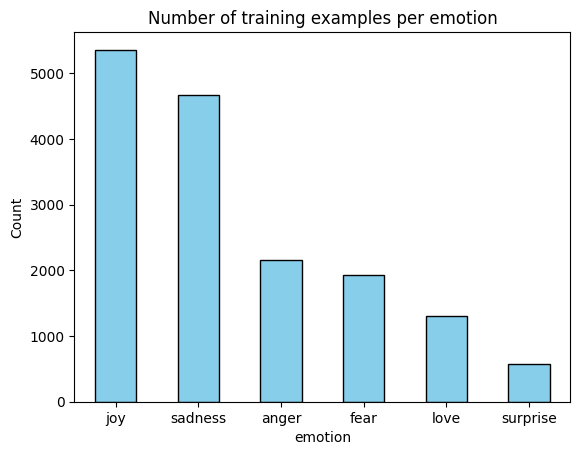

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = ds["train"].to_pandas()
df["emotion"] = df["label"].map(id2label)

# Class distribution
counts = df["emotion"].value_counts()
print(counts)
counts.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Number of training examples per emotion")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: length, dtype: float64


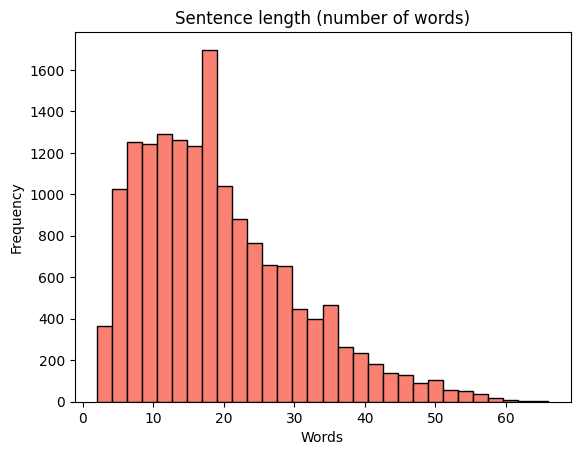

In [5]:
# Sentence length
df["length"] = df["text"].str.split().str.len()
print(df["length"].describe())

df["length"].plot(kind="hist", bins=30, color="salmon", edgecolor="black")
plt.title("Sentence length (number of words)")
plt.xlabel("Words")
plt.show()

In [6]:
# One example sentence for each emotion
for e in labels:
    print(f"{e.upper():9} → {df[df.emotion == e].text.iloc[0]}")

SADNESS   → i didnt feel humiliated
JOY       → i have been with petronas for years i feel that petronas has performed well and made a huge profit
LOVE      → i am ever feeling nostalgic about the fireplace i will know that it is still on the property
ANGER     → im grabbing a minute to post i feel greedy wrong
FEAR      → i feel as confused about life as a teenager or as jaded as a year old man
SURPRISE  → ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny


**Observation:** the dataset is imbalanced. *Joy* and *sadness* have many examples, while *surprise* has very few. Most sentences are short (under 30 words), so a max length of 128 tokens is enough.

## Step 5: Clean the dataset
Check for missing / empty texts and remove duplicate sentences from the training set.
(Lowercasing is not needed: the *uncased* tokenizer does it automatically.)

In [7]:
from datasets import Dataset

train_df = ds["train"].to_pandas()
print("Missing texts:", train_df["text"].isna().sum())
print("Empty texts:  ", (train_df["text"].str.strip() == "").sum())

before = len(train_df)
train_df = train_df.drop_duplicates(subset="text").reset_index(drop=True)
print("Duplicates removed:", before - len(train_df))

ds["train"] = Dataset.from_pandas(train_df, features=ds["train"].features)
print(ds)

Missing texts: 0
Empty texts:   0
Duplicates removed: 31
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 15969
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


---
# Phase 2: Pretrained Model and Fine-Tuning

## Step 6: Load the pretrained model (transfer learning)
DistilBERT already understands English. We add a new output layer with 6 emotions.

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSequenceClassification.from_pretrained(
    name, num_labels=6, id2label=id2label, label2id=label2id
)
print(f"Parameters: {model.num_parameters():,}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 66,958,086


## Step 7: Tokenize (turn text into numbers)

In [9]:
def tokenize(batch):
    return tok(batch["text"], truncation=True, max_length=128)

ds_tok = ds.map(tokenize, batched=True)
print(ds_tok["train"][0]["input_ids"][:15])

Map:   0%|          | 0/15969 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

[101, 1045, 2134, 2102, 2514, 26608, 102]


## Step 8: Fine-tune (about 5–8 minutes)

In [10]:
import numpy as np
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"accuracy": (preds == p.label_ids).mean()}

args = TrainingArguments(
    output_dir="results",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=5e-5,
    eval_strategy="epoch",
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=ds_tok["train"],
    eval_dataset=ds_tok["validation"],
    data_collator=DataCollatorWithPadding(tok),
    compute_metrics=compute_metrics,
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.419965,0.172403,0.932000
2,0.117926,0.131185,0.942000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1000, training_loss=0.26894561004638673, metrics={'train_runtime': 183.457, 'train_samples_per_second': 174.09, 'train_steps_per_second': 5.451, 'total_flos': 429425255669976.0, 'train_loss': 0.26894561004638673, 'epoch': 2.0})

## Step 9: Final test accuracy

In [11]:
test_results = trainer.evaluate(ds_tok["test"])
test_acc = test_results["eval_accuracy"]
print(f"Test accuracy: {test_acc:.2%}")

Training Loss,Validation Loss,Epoch,Accuracy
0.117926,0.146219,2,0.930000


Test accuracy: 93.00%


## Step 10: Confusion matrix

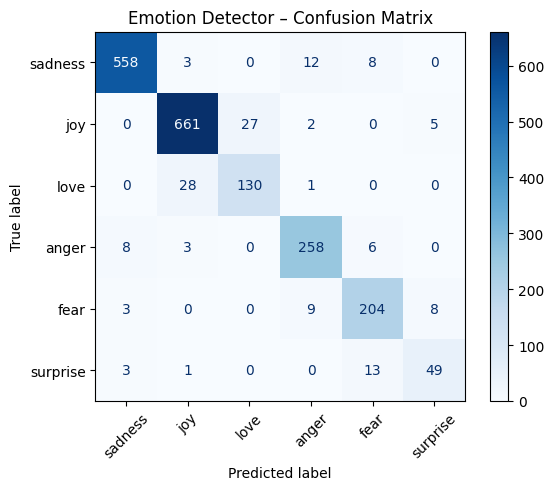

              precision    recall  f1-score   support

     sadness       0.98      0.96      0.97       581
         joy       0.95      0.95      0.95       695
        love       0.83      0.82      0.82       159
       anger       0.91      0.94      0.93       275
        fear       0.88      0.91      0.90       224
    surprise       0.79      0.74      0.77        66

    accuracy                           0.93      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.93      0.93      0.93      2000



In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

pred = trainer.predict(ds_tok["test"])
y_pred = pred.predictions.argmax(axis=1)

ConfusionMatrixDisplay.from_predictions(
    pred.label_ids, y_pred, display_labels=labels, xticks_rotation=45, cmap="Blues"
)
plt.title("Emotion Detector – Confusion Matrix")
plt.show()

print(classification_report(pred.label_ids, y_pred, target_names=labels))

## Step 11: Try it yourself

In [13]:
from transformers import pipeline
clf = pipeline("text-classification", model=model, tokenizer=tok, device=0)

for s in ["I can't believe I passed the exam!",
          "I miss my grandmother so much.",
          "Why would you break my phone?!",
          "I heard footsteps behind me in the dark."]:
    print(s, "→", clf(s)[0])

I can't believe I passed the exam! → {'label': 'joy', 'score': 0.893225371837616}
I miss my grandmother so much. → {'label': 'sadness', 'score': 0.9279805421829224}
Why would you break my phone?! → {'label': 'anger', 'score': 0.5665587186813354}
I heard footsteps behind me in the dark. → {'label': 'fear', 'score': 0.8211331367492676}


## Step 12: Save the fine-tuned model

In [14]:
trainer.save_model("emotion-detector-local")
tok.save_pretrained("emotion-detector-local")
!ls emotion-detector-local

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

config.json	   tokenizer_config.json  training_args.bin
model.safetensors  tokenizer.json


---
# Phase 3: Model Hosting on Hugging Face

## Step 13: Upload the fine-tuned model
It will appear at `huggingface.co/MarwanSalim023/emotion-detector`.

In [15]:
model.push_to_hub("emotion-detector")
tok.push_to_hub("emotion-detector")

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...wx0nr9s/model.safetensors:   0%|          |  574kB /  268MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/MarwanSalim023/emotion-detector/commit/50938a9a767c970cc15ed94ef7c3fa6e43569148', commit_message='Upload tokenizer', commit_description='', oid='50938a9a767c970cc15ed94ef7c3fa6e43569148', pr_url=None, repo_url=RepoUrl('https://huggingface.co/MarwanSalim023/emotion-detector', endpoint='https://huggingface.co', repo_type='model', repo_id='MarwanSalim023/emotion-detector'), pr_revision=None, pr_num=None)

## Step 14: Add a model card (description page)

In [16]:
from huggingface_hub import HfApi

card = f"""---
language: en
license: apache-2.0
base_model: distilbert-base-uncased
datasets:
- dair-ai/emotion
pipeline_tag: text-classification
metrics:
- accuracy
---

# AI Emotion Detector

DistilBERT fine-tuned (transfer learning) on the dair-ai/emotion dataset to classify English text into 6 emotions:
sadness, joy, love, anger, fear, surprise.

- **Base model:** distilbert-base-uncased
- **Dataset:** dair-ai/emotion (16,000 train / 2,000 validation / 2,000 test)
- **Training:** 2 epochs, batch size 32, learning rate 5e-5, Google Colab T4 GPU
- **Test accuracy:** {test_acc:.2%}
- **Live app:** https://ai-emotion-detector-mehrwan.streamlit.app

## Usage

```python
from transformers import pipeline
clf = pipeline("text-classification", model="MarwanSalim023/emotion-detector")
print(clf("I just got my first job offer!"))
```
"""

HfApi().upload_file(
    path_or_fileobj=card.encode(),
    path_in_repo="README.md",
    repo_id="MarwanSalim023/emotion-detector",
)
print("Model card uploaded!")

Model card uploaded!


## Step 15: Verify the uploaded model loads from Hugging Face
This downloads the model fresh from the Hub (not from Colab memory) and tests it.

In [17]:
check = pipeline("text-classification", model="MarwanSalim023/emotion-detector")

for s in ["I am so happy today!", "This makes me really angry."]:
    print(s, "→", check(s)[0])
print("\n✅ Model loaded successfully from Hugging Face!")

config.json:   0%|          | 0.00/910 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

I am so happy today! → {'label': 'joy', 'score': 0.9975332021713257}
This makes me really angry. → {'label': 'anger', 'score': 0.996887743473053}

✅ Model loaded successfully from Hugging Face!
